# LeJEPA with Vision Transformers

The previous project explored a JEPA-style model that predicted latent representations of masked image regions.  
The model avoided complete collapse after adding stronger regularization, but training remained unstable and downstream results were weak.

This project moves to **LeJEPA**, which is designed to address exactly these issues:

- no teacher-student setup
- no EMA target encoder
- no stop-gradient tricks
- a simpler loss formulation
- explicit latent-space regularization through SIGReg

Instead of using a CNN and masked patches, this project follows the LeJEPA minimal example more closely by using:

- a Vision Transformer backbone
- multi-view image augmentations
- an invariance loss between views
- SIGReg to prevent collapse and structure the embedding space

The goal is to train a more stable self-supervised image representation and evaluate it with a linear probe.

For reference to the original LeJEPA project look at https://github.com/galilai-group/lejepa/blob/main/MINIMAL.md

## Section 1: Dataset, Configuration, and Multi-View Pipeline

LeJEPA trains on multiple augmented views of the same image. Instead of masking an image region and predicting a target patch, the model receives several transformed views of one image and learns representations that are both:

- invariant across views
- well-structured in latent space

### 1.1 Project configuration

Important hyperparameters are collected in a configuration class so that experiments can be adjusted from one place. This includes dataset paths, model dimensions, batch size, learning rate, weight decay, number of views, and training epochs.

In [30]:
from dataclasses import dataclass

@dataclass
class LeJEPAConfig:
    # -------------------------
    # General / runtime
    # -------------------------
    seed: int = 42
    num_workers: int = 8

    # -------------------------
    # Dataset
    # -------------------------
    dataset_config: str = "160px"
    data_root: str = "./data"
    image_size: int = 128
    num_classes: int = 10

    # -------------------------
    # Multi-view setup
    # -------------------------
    num_views: int = 4

    # -------------------------
    # Model
    # -------------------------
    backbone_name: str = "vit_small_patch8_224"
    backbone_output_dim: int = 512
    projection_dim: int = 16
    projector_hidden_dim: int = 2048
    drop_path_rate: float = 0.1

    # -------------------------
    # LeJEPA loss
    # -------------------------
    lambda_sigreg: float = 0.02
    sigreg_knots: int = 17
    sigreg_num_projections: int = 256

    # -------------------------
    # Training
    # -------------------------
    batch_size: int = 256
    epochs: int = 300
    learning_rate: float = 2e-3
    weight_decay: float = 5e-2

    # -------------------------
    # Linear probe
    # -------------------------
    probe_learning_rate: float = 1e-3
    probe_weight_decay: float = 1e-7
    probe_epochs: int = 50

    # -------------------------
    # Evaluation / visualization
    # -------------------------
    eval_batch_size: int = 256
    embedding_subset_size: int = 2000
    num_visual_examples: int = 5


cfg = LeJEPAConfig()

### 1.2 Imports and reproducibility

The main dependencies are imported and random seeds are fixed. 

In [2]:
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.transforms import v2
from datasets import load_dataset

random.seed(cfg.seed)
np.random.seed(cfg.seed)
torch.manual_seed(cfg.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### 1.3 Loading Imagenette

Imagenette is a smaller 10-class subset of ImageNet. It is useful for this project because it is significantly more realistic than CIFAR-10, but still small enough for fast experimentation on a single GPU.
The dataset contains images and labels. Labels will not be used for LeJEPA pretraining, but they will later be used for linear evaluation.

In [3]:
from torchvision.datasets import ImageFolder
from pathlib import Path

data_root = Path(cfg.data_root) / "imagenette2-160"

train_dir = data_root / "train"
val_dir = data_root / "val"

assert train_dir.exists(), f"Train directory not found: {train_dir}"
assert val_dir.exists(), f"Val directory not found: {val_dir}"

train_dataset_raw = ImageFolder(train_dir)
val_dataset_raw = ImageFolder(val_dir)

print(f"Train samples: {len(train_dataset_raw)}")
print(f"Val samples:   {len(val_dataset_raw)}")
print(f"Classes:       {len(train_dataset_raw.classes)}")

Train samples: 9469
Val samples:   3925
Classes:       10


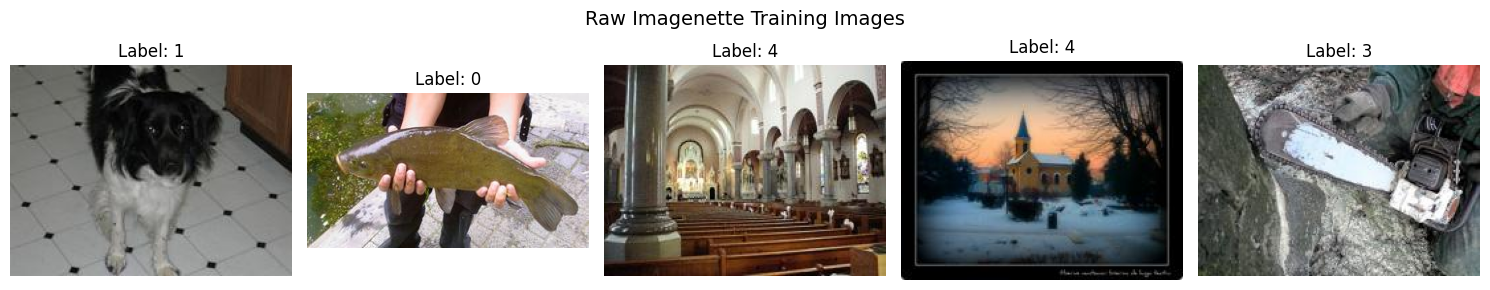

In [4]:
num_examples = cfg.num_visual_examples
indices = random.sample(range(len(train_dataset_raw)), num_examples)

fig, axes = plt.subplots(1, num_examples, figsize=(3 * num_examples, 3))

for ax, idx in zip(axes, indices):
    img, label = train_dataset_raw[idx]  

    ax.imshow(img)
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.suptitle("Raw Imagenette Training Images", fontsize=14)
plt.tight_layout()
plt.show()

### 1.4 Defining train and test transforms

The training transform creates strong augmented views of each image. 
The test transform uses resizing and center cropping to produce deterministic images for evaluation. The training transform is intentionally strong because LeJEPA should learn representations that remain stable across different views of the same image.

In [5]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(cfg.image_size, scale=(0.08, 1.0)),
    v2.RandomApply([
        v2.ColorJitter(
            brightness=0.8,
            contrast=0.8,
            saturation=0.8,
            hue=0.2
        )
    ], p=0.8),
    v2.RandomGrayscale(p=0.2),
    v2.RandomApply([
        v2.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))
    ], p=0.5),
    v2.RandomApply([
        v2.RandomSolarize(threshold=128)
    ], p=0.2),
    v2.RandomHorizontalFlip(),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = v2.Compose([
    v2.Resize(cfg.image_size),
    v2.CenterCrop(cfg.image_size),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### 1.6 Defining a multi-view dataset

For each image, the dataset returns several independently augmented views.
The output shape for one sample will be:

`[num_views, 3, image_size, image_size]`

In [6]:
class ImagenetteMultiViewDataset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, num_views=cfg.num_views, train=True):
        self.ds = base_dataset
        self.num_views = num_views
        self.transform = train_transform if train else test_transform

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        img, label = self.ds[idx]

        views = torch.stack([
            self.transform(img) for _ in range(self.num_views)
        ])

        return views, label


train_dataset = ImagenetteMultiViewDataset(
    base_dataset=train_dataset_raw,
    num_views=cfg.num_views,
    train=True
)

test_dataset = ImagenetteMultiViewDataset(
    base_dataset=val_dataset_raw,
    num_views=1,
    train=False
)

views, label = train_dataset[0]

print("Views shape:", views.shape)
print("Label:", label)

Views shape: torch.Size([4, 3, 128, 128])
Label: 0


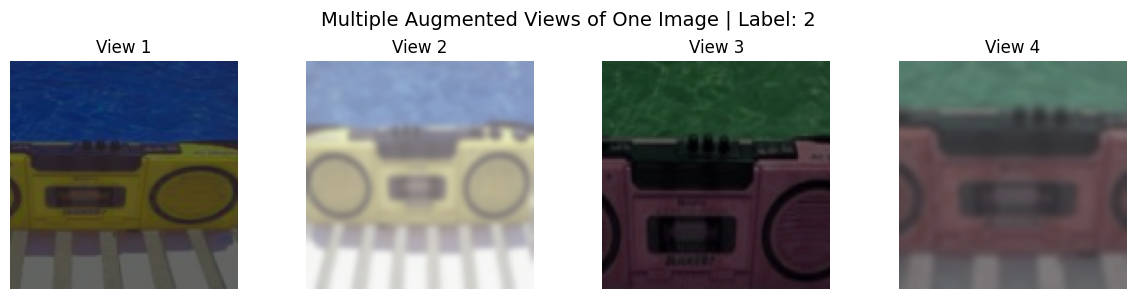

In [7]:
# Helper function to undo normalization for visualization
def denormalize(img_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (img_tensor.cpu() * std + mean).clamp(0, 1)


sample_idx = random.randint(0, len(train_dataset) - 1)
views, label = train_dataset[sample_idx]

fig, axes = plt.subplots(1, cfg.num_views, figsize=(3 * cfg.num_views, 3))

for i in range(cfg.num_views):
    img = denormalize(views[i]).permute(1, 2, 0).numpy()
    axes[i].imshow(img)
    axes[i].set_title(f"View {i+1}")
    axes[i].axis("off")

plt.suptitle(f"Multiple Augmented Views of One Image | Label: {label}", fontsize=14)
plt.tight_layout()
plt.show()

### 1.6 Creating dataloaders

The dataloaders provide batches of multi-view images for pretraining and single-view images for evaluation.

In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.batch_size,
    shuffle=True,
    drop_last=True,
    num_workers=cfg.num_workers,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(cfg.num_workers > 0),
    prefetch_factor=2 if cfg.num_workers > 0 else None
)

test_loader = DataLoader(
    test_dataset,
    batch_size=cfg.eval_batch_size,
    shuffle=False,
    drop_last=False,
    num_workers=cfg.num_workers,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(cfg.num_workers > 0),
    prefetch_factor=2 if cfg.num_workers > 0 else None
)

batch_views, batch_labels = next(iter(train_loader))

print("Batch views shape:", batch_views.shape)
print("Batch labels shape:", batch_labels.shape)

Batch views shape: torch.Size([256, 4, 3, 128, 128])
Batch labels shape: torch.Size([256])


## Section 2: Vision Transformer Encoder

LeJEPA can be trained with many different backbone architectures.  
This project uses a Vision Transformer (ViT), following the minimal LeJEPA example.

The encoder maps each image view to:

- a backbone embedding used for linear evaluation
- a projected embedding used for the LeJEPA objective

### 2.1 Defining the ViT encoder

The encoder receives a tensor of shape:

`[batch_size, num_views, 3, image_size, image_size]`

It flattens the batch and view dimensions, applies the ViT backbone, and then reshapes the projected embeddings back into a multi-view structure.

In [9]:
import torch.nn as nn
import torch.nn.functional as F
import timm

class ViTEncoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()

        self.backbone = timm.create_model(
            cfg.backbone_name,
            pretrained=False,
            num_classes=cfg.backbone_output_dim,
            drop_path_rate=cfg.drop_path_rate,
            img_size=cfg.image_size
        )

        self.proj = nn.Sequential(
            nn.Linear(cfg.backbone_output_dim, cfg.projector_hidden_dim),
            nn.BatchNorm1d(cfg.projector_hidden_dim),
            nn.ReLU(),
            nn.Linear(cfg.projector_hidden_dim, cfg.projector_hidden_dim),
            nn.BatchNorm1d(cfg.projector_hidden_dim),
            nn.ReLU(),
            nn.Linear(cfg.projector_hidden_dim, cfg.projection_dim)
        )

    def forward(self, x):
        batch_size, num_views = x.shape[:2]

        x = x.flatten(0, 1)          # [B * V, C, H, W]
        emb = self.backbone(x)       # [B * V, backbone_output_dim]
        proj = self.proj(emb)        # [B * V, projection_dim]

        proj = proj.reshape(batch_size, num_views, -1)
        proj = proj.transpose(0, 1)  # [V, B, projection_dim]

        return emb, proj

The backbone embedding is kept in flattened form because it will later be used for online linear probing.
The projected representation is reshaped to `[num_views, batch_size, projection_dim]`, which is convenient for computing the invariance loss across views.

### 2.2 Initializing the model and testing the forward pass

A single training batch is passed through the encoder to verify that the tensor shapes match the expected LeJEPA format. Expected shapes:

- input batch: `[batch_size, num_views, 3, image_size, image_size]`
- backbone embeddings: `[batch_size × num_views, backbone_output_dim]`
- projected embeddings: `[num_views, batch_size, projection_dim]`

These projected embeddings will be used in the LeJEPA loss in the next sections.

In [10]:
from torch.amp import autocast

net = ViTEncoder(cfg).to(device)
net.eval()

batch_views, batch_labels = next(iter(train_loader))
batch_views = batch_views.to(device, non_blocking=True)

with torch.no_grad():
    with autocast(device_type=device.type, dtype=torch.bfloat16, enabled=(device.type == "cuda")):
        emb, proj = net(batch_views)

proj_flat = proj.transpose(0, 1).reshape(-1, cfg.projection_dim)
proj_flat = proj_flat.detach().cpu().float()

mean_per_dim = proj_flat.mean(dim=0)
std_per_dim = proj_flat.std(dim=0)

print("Input batch shape:     ", batch_views.shape)
print("Backbone embeddings:   ", emb.shape)
print("Projected embeddings:  ", proj.shape)

print(f"Projection mean (average over dims): {mean_per_dim.mean().item():.4f}")
print(f"Projection std  (average over dims): {std_per_dim.mean().item():.4f}")
print(f"Min std over dims:                  {std_per_dim.min().item():.4f}")
print(f"Max std over dims:                  {std_per_dim.max().item():.4f}")

Input batch shape:      torch.Size([256, 4, 3, 128, 128])
Backbone embeddings:    torch.Size([1024, 512])
Projected embeddings:   torch.Size([4, 256, 16])
Projection mean (average over dims): 0.0008
Projection std  (average over dims): 0.0229
Min std over dims:                  0.0122
Max std over dims:                  0.0371


## Section 3: Projection Pipeline and Initial Representation Checks

The Vision Transformer from Section 2 produces two outputs:

- backbone embeddings, which will later be used for linear evaluation
- projected embeddings, which are used for the LeJEPA objective

Before implementing the LeJEPA loss, it is useful to inspect the projected representation space.

### 3.1 Extracting embeddings from a batch

A batch of multi-view images is passed through the ViT encoder.
The projected embeddings should have shape:

`[num_views, batch_size, projection_dim]`

In [11]:
batch_views, batch_labels = next(iter(train_loader))
batch_views = batch_views.to(device)

net.eval()

with torch.no_grad():
    emb, proj = net(batch_views)

print("Input views shape:       ", batch_views.shape)
print("Backbone embedding shape:", emb.shape)
print("Projection shape:        ", proj.shape)

Input views shape:        torch.Size([256, 4, 3, 128, 128])
Backbone embedding shape: torch.Size([1024, 512])
Projection shape:         torch.Size([4, 256, 16])


In [12]:
proj_flat = proj.transpose(0, 1).reshape(-1, cfg.projection_dim).detach().cpu()
print("Flattened projection shape:", proj_flat.shape)

Flattened projection shape: torch.Size([1024, 16])


In [13]:
mean_per_dim = proj_flat.mean(dim=0)
std_per_dim = proj_flat.std(dim=0)

print(f"Mean over dimensions:      {mean_per_dim.mean().item():.4f}")
print(f"Mean std over dimensions:  {std_per_dim.mean().item():.4f}")
print(f"Min std over dimensions:   {std_per_dim.min().item():.4f}")
print(f"Max std over dimensions:   {std_per_dim.max().item():.4f}")

Mean over dimensions:      0.0006
Mean std over dimensions:  0.0231
Min std over dimensions:   0.0126
Max std over dimensions:   0.0364


### 3.2 Measuring view similarity before training

LeJEPA will later encourage different views of the same image to produce similar projected embeddings.
Before training, these similarities provide a useful baseline.

In [14]:
# Normalize projections for cosine similarity
proj_norm = F.normalize(proj, dim=-1)

# Compare each view to the first view
base_view = proj_norm[0]  # [B, D]

view_similarities = []

for v in range(1, cfg.num_views):
    sim = F.cosine_similarity(base_view, proj_norm[v], dim=1)
    view_similarities.append(sim.mean().item())

for v, sim in enumerate(view_similarities, start=2):
    print(f"Mean cosine similarity: View 1 vs View {v}: {sim:.4f}")

Mean cosine similarity: View 1 vs View 2: 0.7035
Mean cosine similarity: View 1 vs View 3: 0.7275
Mean cosine similarity: View 1 vs View 4: 0.7099


### 3.5 Visualizing initial projected embeddings with PCA

A two-dimensional PCA projection provides a first look at the untrained projection space.
This plot serves as a baseline for later comparison after LeJEPA training.

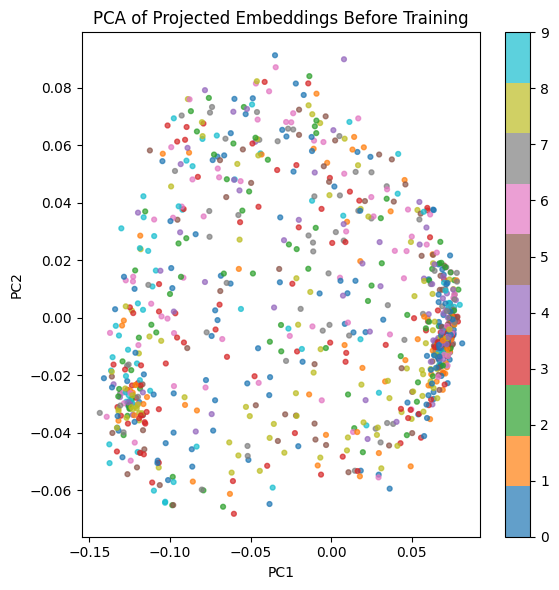

In [15]:
from sklearn.decomposition import PCA

labels_repeated = batch_labels.repeat_interleave(cfg.num_views).cpu()

pca = PCA(n_components=2)
proj_2d = pca.fit_transform(proj_flat.numpy())

plt.figure(figsize=(6, 6))
scatter = plt.scatter(
    proj_2d[:, 0],
    proj_2d[:, 1],
    c=labels_repeated,
    cmap="tab10",
    s=12,
    alpha=0.7
)

plt.title("PCA of Projected Embeddings Before Training")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(scatter, ticks=range(cfg.num_classes))
plt.tight_layout()
plt.show()

## Section 4: LeJEPA Objective

LeJEPA combines two complementary objectives:

1. **Invariance loss**  
   Different augmented views of the same image should produce similar projected embeddings.

2. **SIGReg loss**  
   The projected embeddings should remain well-structured and avoid collapse.

The combined loss is:

$$
\mathcal{L}_{LeJEPA} = (1 - \lambda)\mathcal{L}_{inv} + \lambda \mathcal{L}_{SIGReg}
$$

This section implements both loss terms and tests them on one batch before training.

### 4.1 Implementing the loss

The invariance loss encourages all views of the same image to align in projection space.
SIGReg regularizes the projected embeddings by comparing random one-dimensional projections of the embedding distribution to a Gaussian reference distribution.

In [16]:
def invariance_loss(proj):
    """
    proj: tensor of shape [num_views, batch_size, projection_dim]
    """
    view_mean = proj.mean(dim=0, keepdim=True)
    loss = (proj - view_mean).pow(2).mean()
    return loss

class SIGReg(nn.Module):
    def __init__(self, knots=17, num_projections=256):
        super().__init__()

        t = torch.linspace(0, 3, knots, dtype=torch.float32)
        dt = 3 / (knots - 1)

        weights = torch.full((knots,), 2 * dt, dtype=torch.float32)
        weights[[0, -1]] = dt

        window = torch.exp(-t.square() / 2.0)

        self.num_projections = num_projections
        self.register_buffer("t", t)
        self.register_buffer("phi", window)
        self.register_buffer("weights", weights * window)

    def forward(self, proj):
        """
        proj: tensor of shape [num_views, batch_size, projection_dim]
        """
        proj_flat = proj.transpose(0, 1).reshape(-1, proj.size(-1))

        A = torch.randn(
            proj_flat.size(-1),
            self.num_projections,
            device=proj_flat.device
        )
        A = A / A.norm(p=2, dim=0, keepdim=True)

        x_t = (proj_flat @ A).unsqueeze(-1) * self.t

        err = (
            (x_t.cos().mean(dim=0) - self.phi).pow(2)
            + x_t.sin().mean(dim=0).pow(2)
        )

        statistic = (err @ self.weights) * proj_flat.size(0)
        return statistic.mean()

### 4.2 Combining invariance and SIGReg

The final LeJEPA loss is a weighted combination of the invariance loss and SIGReg.
The weight $\lambda$ controls how strongly the latent distribution is regularized.

In [17]:
sigreg = SIGReg(
    knots=cfg.sigreg_knots,
    num_projections=cfg.sigreg_num_projections
).to(device)


def lejepa_loss(proj, lambda_sigreg=cfg.lambda_sigreg):
    inv = invariance_loss(proj)
    sig = sigreg(proj)
    total = (1.0 - lambda_sigreg) * inv + lambda_sigreg * sig
    return total, inv.detach(), sig.detach()

### 4.3 Testing the loss on one batch

Before starting training, the loss is evaluated on one batch to verify that all components produce valid values.

In [18]:
net.eval()

batch_views, batch_labels = next(iter(train_loader))
batch_views = batch_views.to(device)

with torch.no_grad():
    emb, proj = net(batch_views)
    total_loss, inv_loss_value, sigreg_loss_value = lejepa_loss(proj)

print(f"Total LeJEPA loss: {total_loss.item():.4f}")
print(f"Invariance loss:   {inv_loss_value.item():.4f}")
print(f"SIGReg loss:       {sigreg_loss_value.item():.4f}")

Total LeJEPA loss: 8.2366
Invariance loss:   0.0004
SIGReg loss:       411.8108


### 4.4 Inspecting embedding spread

A simple way to check for collapse is to measure the standard deviation of projected embeddings across the batch.
Collapsed representations have near-zero standard deviation.

In [19]:
proj_flat = proj.transpose(0, 1).reshape(-1, cfg.projection_dim).detach()

std_per_dim = proj_flat.std(dim=0)
mean_std = std_per_dim.mean().item()
min_std = std_per_dim.min().item()
max_std = std_per_dim.max().item()

print(f"Mean projection std: {mean_std:.4f}")
print(f"Min projection std:  {min_std:.4f}")
print(f"Max projection std:  {max_std:.4f}")

Mean projection std: 0.0233
Min projection std:  0.0123
Max projection std:  0.0365


## Section 5: Training LeJEPA and Monitoring Stability

The LeJEPA model can now be trained using the objective defined in Section 4.
The most important quantities are:

- total LeJEPA loss
- invariance loss
- SIGReg loss
- online probe loss
- online probe accuracy
- projection standard deviation

These metrics make it possible to evaluate both optimization progress and representation stability.

### 5.1 Defining the online linear probe

The online linear probe is trained during self-supervised pretraining.
The probe receives detached backbone embeddings, so it does not influence the encoder. It provides a quick estimate of representation quality during training.

The probe is intentionally simple.
If the backbone embeddings become semantically useful, the online probe accuracy should improve during training.

In [20]:
class OnlineLinearProbe(nn.Module):
    def __init__(self, embedding_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(embedding_dim),
            nn.Linear(embedding_dim, num_classes)
        )

    def forward(self, x):
        return self.net(x)


online_probe = OnlineLinearProbe(
    embedding_dim=cfg.backbone_output_dim,
    num_classes=cfg.num_classes
).to(device)

### 5.2 Defining optimizer and scheduler

LeJEPA uses one optimizer with two parameter groups:

- encoder parameters
- online probe parameters

The encoder uses the main learning rate and weight decay.  
The probe uses its own learning rate and a much smaller weight decay.

The schedule starts with a short warmup and then follows cosine decay.
This helps stabilize optimization early in training.

In [21]:
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR

encoder_group = {
    "params": net.parameters(),
    "lr": cfg.learning_rate,
    "weight_decay": cfg.weight_decay
}

probe_group = {
    "params": online_probe.parameters(),
    "lr": cfg.probe_learning_rate,
    "weight_decay": cfg.probe_weight_decay
}

optimizer = torch.optim.AdamW([encoder_group, probe_group])

warmup_steps = len(train_loader)
total_steps = len(train_loader) * cfg.epochs

warmup_scheduler = LinearLR(
    optimizer,
    start_factor=0.01,
    total_iters=warmup_steps
)

cosine_scheduler = CosineAnnealingLR(
    optimizer,
    T_max=max(1, total_steps - warmup_steps),
    eta_min=1e-3
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[warmup_steps]
)

print(f"Warmup steps: {warmup_steps}")
print(f"Total steps:  {total_steps}")

Warmup steps: 36
Total steps:  10800


### 5.3 Setting up mixed precision

Mixed precision reduces memory usage and can speed up training on modern NVIDIA GPUs.
The model uses bfloat16 autocasting when CUDA is available.

In [22]:
from torch.amp import GradScaler

use_cuda = device.type == "cuda"
amp_dtype = torch.bfloat16 if use_cuda else torch.float32

# GradScaler is mainly needed for float16.
# With bfloat16, scaling is usually not necessary, but keeping it disabled is clean.
scaler = GradScaler(enabled=False)

print(f"CUDA available: {use_cuda}")
print(f"AMP dtype: {amp_dtype}")

CUDA available: True
AMP dtype: torch.bfloat16


### 5.4 Training loop

For each batch:

1. multiple views are passed through the ViT encoder
2. the LeJEPA loss is computed from projected embeddings
3. the online probe is trained on detached backbone embeddings
4. the optimizer updates both the encoder and the probe
5. metrics are accumulated for visualization

In [23]:
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

history = {
    "lejepa": [],
    "invariance": [],
    "sigreg": [],
    "probe_loss": [],
    "probe_acc": [],
    "proj_std": [],
    "lr": []
}

for epoch in range(cfg.epochs):
    net.train()
    online_probe.train()

    running_lejepa = 0.0
    running_inv = 0.0
    running_sigreg = 0.0
    running_probe_loss = 0.0
    running_probe_correct = 0
    running_probe_total = 0
    running_proj_std = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{cfg.epochs}",
        leave=False
    )

    for views, labels in progress_bar:
        views = views.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with autocast(device_type=device.type, dtype=amp_dtype, enabled=use_cuda):
            emb, proj = net(views)

            loss_lejepa, loss_inv, loss_sig = lejepa_loss(
                proj,
                lambda_sigreg=cfg.lambda_sigreg
            )

            # Online probe uses detached embeddings so probe gradients do not update the encoder.
            repeated_labels = labels.repeat_interleave(cfg.num_views)
            probe_logits = online_probe(emb.detach())
            loss_probe = F.cross_entropy(probe_logits, repeated_labels)

            loss = loss_lejepa + loss_probe

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()

        with torch.no_grad():
            proj_flat = proj.transpose(0, 1).reshape(-1, cfg.projection_dim)
            batch_proj_std = proj_flat.std(dim=0).mean().item()

            probe_preds = probe_logits.argmax(dim=1)
            probe_correct = (probe_preds == repeated_labels).sum().item()
            probe_total = repeated_labels.size(0)

        running_lejepa += loss_lejepa.item()
        running_inv += loss_inv.item()
        running_sigreg += loss_sig.item()
        running_probe_loss += loss_probe.item()
        running_probe_correct += probe_correct
        running_probe_total += probe_total
        running_proj_std += batch_proj_std

        current_lr = optimizer.param_groups[0]["lr"]

        progress_bar.set_postfix(
            lejepa=loss_lejepa.item(),
            inv=loss_inv.item(),
            sig=loss_sig.item(),
            probe=loss_probe.item(),
            acc=probe_correct / probe_total,
            std=batch_proj_std,
            lr=current_lr
        )

    num_batches = len(train_loader)

    epoch_lejepa = running_lejepa / num_batches
    epoch_inv = running_inv / num_batches
    epoch_sigreg = running_sigreg / num_batches
    epoch_probe_loss = running_probe_loss / num_batches
    epoch_probe_acc = running_probe_correct / running_probe_total
    epoch_proj_std = running_proj_std / num_batches
    epoch_lr = optimizer.param_groups[0]["lr"]

    history["lejepa"].append(epoch_lejepa)
    history["invariance"].append(epoch_inv)
    history["sigreg"].append(epoch_sigreg)
    history["probe_loss"].append(epoch_probe_loss)
    history["probe_acc"].append(epoch_probe_acc)
    history["proj_std"].append(epoch_proj_std)
    history["lr"].append(epoch_lr)

    print(
        f"Epoch {epoch + 1:03d} | "
        f"LeJEPA: {epoch_lejepa:.4f} | "
        f"Inv: {epoch_inv:.4f} | "
        f"SIGReg: {epoch_sigreg:.4f} | "
        f"Probe Loss: {epoch_probe_loss:.4f} | "
        f"Probe Acc: {epoch_probe_acc:.4f} | "
        f"Proj Std: {epoch_proj_std:.4f}"
    )

Epoch 1/300:   0%|          | 0/36 [00:03<?, ?it/s]

Epoch 001 | LeJEPA: 1.5720 | Inv: 0.5396 | SIGReg: 52.1771 | Probe Loss: 2.3415 | Probe Acc: 0.1213 | Proj Std: 0.9065


Epoch 2/300:   0%|          | 0/36 [00:00<?, ?it/s]

Epoch 002 | LeJEPA: 0.9372 | Inv: 0.5537 | SIGReg: 19.7309 | Probe Loss: 2.2596 | Probe Acc: 0.1647 | Proj Std: 0.9316


Epoch 3/300:   0%|          | 0/36 [00:00<?, ?it/s]

...

Epoch 298 | LeJEPA: 0.1817 | Inv: 0.1386 | SIGReg: 2.2949 | Probe Loss: 0.8140 | Probe Acc: 0.7411 | Proj Std: 0.9744


Epoch 299/300:   0%|          | 0/36 [00:00<?, ?it/s]

Epoch 299 | LeJEPA: 0.1831 | Inv: 0.1391 | SIGReg: 2.3420 | Probe Loss: 0.7823 | Probe Acc: 0.7553 | Proj Std: 0.9749


Epoch 300/300:   0%|          | 0/36 [00:00<?, ?it/s]

Epoch 300 | LeJEPA: 0.1831 | Inv: 0.1399 | SIGReg: 2.2986 | Probe Loss: 0.7838 | Probe Acc: 0.7483 | Proj Std: 0.9738


### 5.5 Visualizing LeJEPA training losses

The LeJEPA loss is composed of the invariance term and the SIGReg term.
The following plots show how these terms evolve during training.

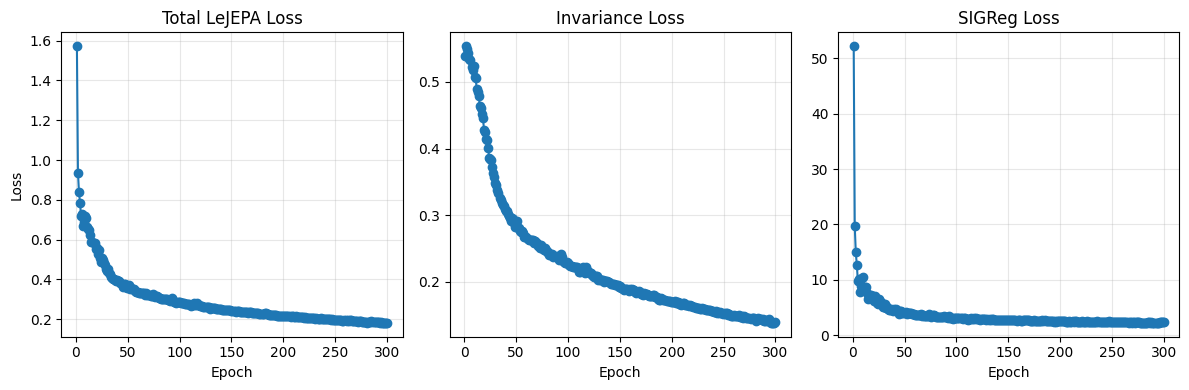

In [24]:
epochs = range(1, len(history["lejepa"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(epochs, history["lejepa"], marker="o")
plt.title("Total LeJEPA Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(epochs, history["invariance"], marker="o")
plt.title("Invariance Loss")
plt.xlabel("Epoch")
plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(epochs, history["sigreg"], marker="o")
plt.title("SIGReg Loss")
plt.xlabel("Epoch")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

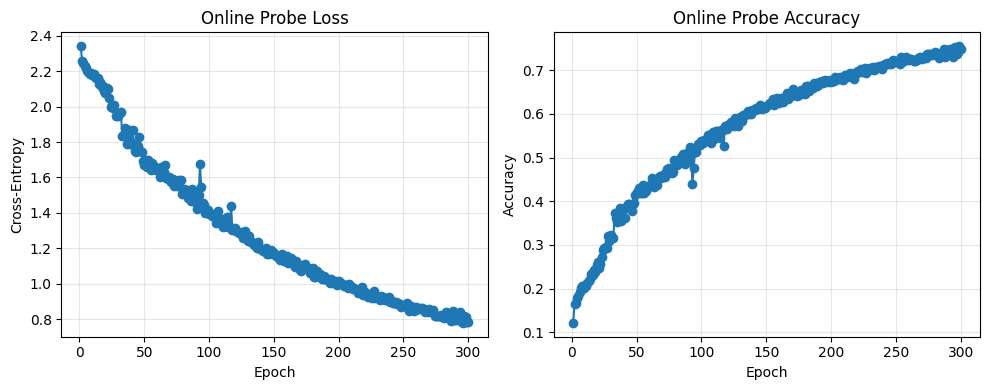

In [25]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["probe_loss"], marker="o")
plt.title("Online Probe Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy")
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["probe_acc"], marker="o")
plt.title("Online Probe Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.6 Monitoring projection spread

The projection standard deviation tracks whether the projected embeddings remain spread out.
A collapse would appear as a standard deviation close to zero.

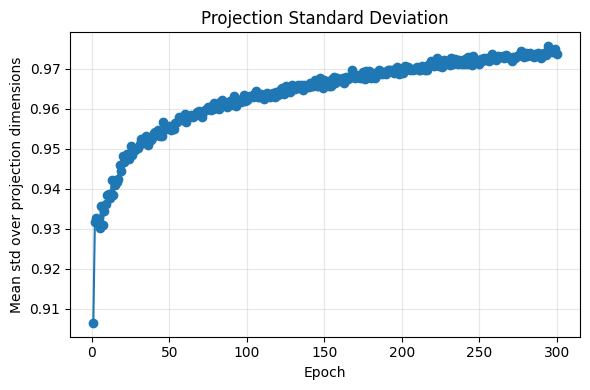

In [26]:
plt.figure(figsize=(6, 4))
plt.plot(epochs, history["proj_std"], marker="o")
plt.title("Projection Standard Deviation")
plt.xlabel("Epoch")
plt.ylabel("Mean std over projection dimensions")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Section 6: Linear Evaluation

After self-supervised pretraining, the quality of the learned representations is evaluated using a linear probe.

A linear classifier is trained on top of the frozen backbone embeddings.  
The encoder weights are not updated during this process.

This is a standard evaluation protocol in self-supervised learning.

### 6.1 Freezing the encoder and feature extraction

- The pretrained encoder is frozen to ensure that only the linear classifier is trained.
- Backbone embeddings are extracted for both training and validation datasets. Only a single view per image is used for evaluation.

In [28]:
for param in net.parameters():
    param.requires_grad = False

net.eval()

train_eval_dataset = ImagenetteMultiViewDataset(
    base_dataset=train_dataset_raw,
    num_views=1,
    train=False
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=cfg.eval_batch_size,
    shuffle=False,
    drop_last=False,
    num_workers=cfg.num_workers,
    pin_memory=torch.cuda.is_available()
)

def extract_features(loader, net, device):
    features = []
    labels = []

    net.eval()

    with torch.inference_mode():
        for views, target in tqdm(loader, desc="Extracting features"):
            views = views.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)

            with autocast(device_type=device.type, dtype=torch.bfloat16, enabled=device.type == "cuda"):
                emb, _ = net(views)

            features.append(emb.float().cpu())
            labels.append(target.cpu())

    features = torch.cat(features, dim=0)
    labels = torch.cat(labels, dim=0)

    return features, labels


train_features, train_labels = extract_features(train_eval_loader, net, device)
val_features, val_labels = extract_features(test_loader, net, device)

print("Train features:", train_features.shape)
print("Val features:", val_features.shape)

Extracting features:   0%|          | 0/37 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/16 [00:00<?, ?it/s]

Train features: torch.Size([9469, 512])
Val features: torch.Size([3925, 512])


### 6.2 Defining the linear classifier and training the probe

A simple linear layer is used for classification. This ensures that performance reflects the quality of the learned representation, not model complexity.

In [31]:
linear_probe = nn.Sequential(
    nn.LayerNorm(cfg.backbone_output_dim),
    nn.Linear(cfg.backbone_output_dim, cfg.num_classes)
).to(device)

optimizer_probe = torch.optim.AdamW(
    linear_probe.parameters(),
    lr=cfg.probe_learning_rate,
    weight_decay=cfg.probe_weight_decay
)

train_features = train_features.to(device)
train_labels = train_labels.to(device)

val_features = val_features.to(device)
val_labels = val_labels.to(device)

probe_dataset = torch.utils.data.TensorDataset(train_features, train_labels)

probe_loader = DataLoader(
    probe_dataset,
    batch_size=cfg.eval_batch_size,
    shuffle=True,
    drop_last=False
)

probe_history = {
    "train_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(cfg.probe_epochs):
    linear_probe.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for x_batch, y_batch in probe_loader:
        logits = linear_probe(x_batch)
        loss = F.cross_entropy(logits, y_batch)

        optimizer_probe.zero_grad()
        loss.backward()
        optimizer_probe.step()

        preds = logits.argmax(dim=1)

        total_loss += loss.item() * x_batch.size(0)
        correct += (preds == y_batch).sum().item()
        total += x_batch.size(0)

    train_loss = total_loss / total
    train_acc = correct / total

    linear_probe.eval()
    with torch.inference_mode():
        val_logits = linear_probe(val_features)
        val_preds = val_logits.argmax(dim=1)
        val_acc = (val_preds == val_labels).float().mean().item()

    probe_history["train_loss"].append(train_loss)
    probe_history["train_acc"].append(train_acc)
    probe_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1:03d} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch 001 | Loss: 1.8282 | Train Acc: 0.5316 | Val Acc: 0.7679
Epoch 002 | Loss: 1.1094 | Train Acc: 0.7928 | Val Acc: 0.8013
Epoch 003 | Loss: 0.8261 | Train Acc: 0.8127 | Val Acc: 0.8143
Epoch 004 | Loss: 0.7072 | Train Acc: 0.8190 | Val Acc: 0.8048
Epoch 005 | Loss: 0.6433 | Train Acc: 0.8228 | Val Acc: 0.8229
Epoch 006 | Loss: 0.6033 | Train Acc: 0.8303 | Val Acc: 0.8242
Epoch 007 | Loss: 0.5804 | Train Acc: 0.8316 | Val Acc: 0.8219
Epoch 008 | Loss: 0.5639 | Train Acc: 0.8308 | Val Acc: 0.8288
Epoch 009 | Loss: 0.5501 | Train Acc: 0.8338 | Val Acc: 0.8247
Epoch 010 | Loss: 0.5423 | Train Acc: 0.8353 | Val Acc: 0.8278
Epoch 011 | Loss: 0.5328 | Train Acc: 0.8346 | Val Acc: 0.8296
Epoch 012 | Loss: 0.5241 | Train Acc: 0.8374 | Val Acc: 0.8321
Epoch 013 | Loss: 0.5229 | Train Acc: 0.8364 | Val Acc: 0.8275
Epoch 014 | Loss: 0.5164 | Train Acc: 0.8394 | Val Acc: 0.8316
Epoch 015 | Loss: 0.5153 | Train Acc: 0.8398 | Val Acc: 0.8329
Epoch 016 | Loss: 0.5098 | Train Acc: 0.8402 | Val Acc:

### 6.3 Evaluation and visualization

In [32]:
linear_probe.eval()

with torch.inference_mode():
    logits = linear_probe(val_features)
    preds = logits.argmax(dim=1)
    val_acc = (preds == val_labels).float().mean().item()

print(f"Final validation accuracy: {val_acc:.4f}")

Final validation accuracy: 0.8331


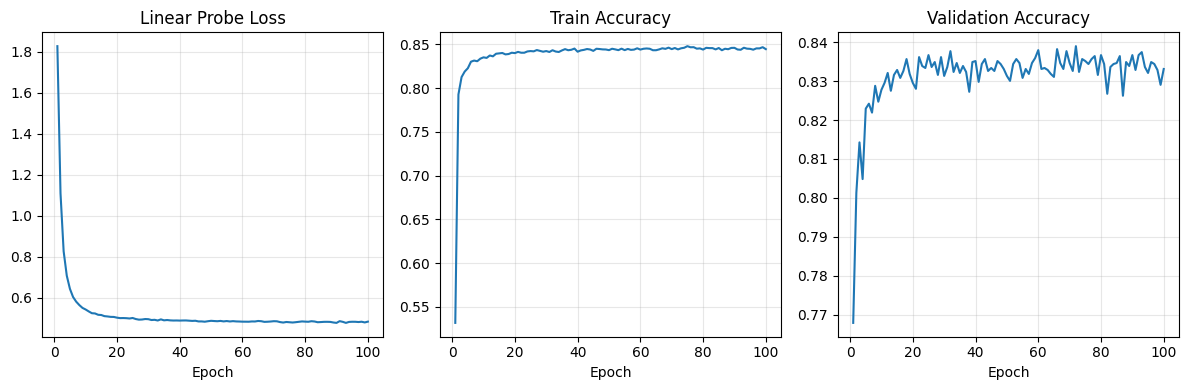

In [33]:
epochs = range(1, cfg.probe_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(epochs, probe_history["train_loss"])
plt.title("Linear Probe Loss")
plt.xlabel("Epoch")
plt.grid(alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(epochs, probe_history["train_acc"])
plt.title("Train Accuracy")
plt.xlabel("Epoch")
plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(epochs, probe_history["val_acc"])
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Section 7: Latent Space Analysis

Beyond quantitative evaluation, it is useful to visually inspect the learned embedding space.
The goal of this section is to understand:

- whether samples from the same class cluster together  
- whether the representation space is well-structured  
- how LeJEPA organizes semantic information  

### 7.1 Preparing embeddings for visualization

A subset of validation embeddings is used to keep visualization efficient.

In [34]:
num_samples = min(cfg.embedding_subset_size, val_features.shape[0])

indices = torch.randperm(val_features.shape[0])[:num_samples]

subset_features = val_features[indices].cpu()
subset_labels = val_labels[indices].cpu()

print("Subset shape:", subset_features.shape)

Subset shape: torch.Size([2000, 512])


### 7.2 PCA projection

Principal Component Analysis (PCA) reduces the high-dimensional embeddings.
This provides a first view of the global structure of the embedding space.

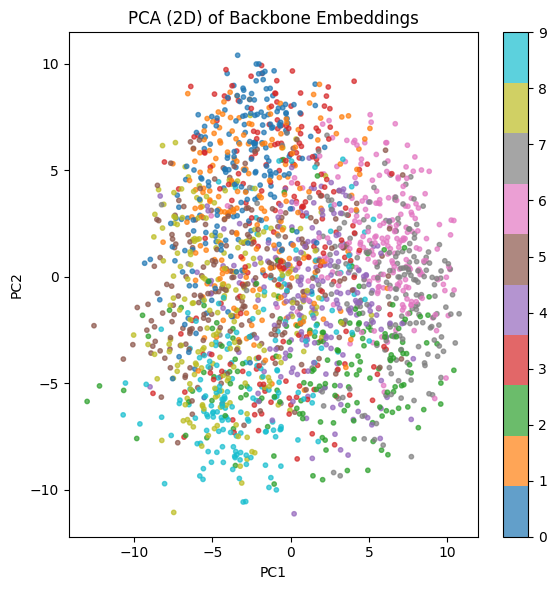

In [35]:
from sklearn.decomposition import PCA

pca_2d = PCA(n_components=2)
features_2d = pca_2d.fit_transform(subset_features.numpy())

plt.figure(figsize=(6, 6))
scatter = plt.scatter(
    features_2d[:, 0],
    features_2d[:, 1],
    c=subset_labels,
    cmap="tab10",
    s=10,
    alpha=0.7
)

plt.title("PCA (2D) of Backbone Embeddings")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(scatter)
plt.tight_layout()
plt.show()

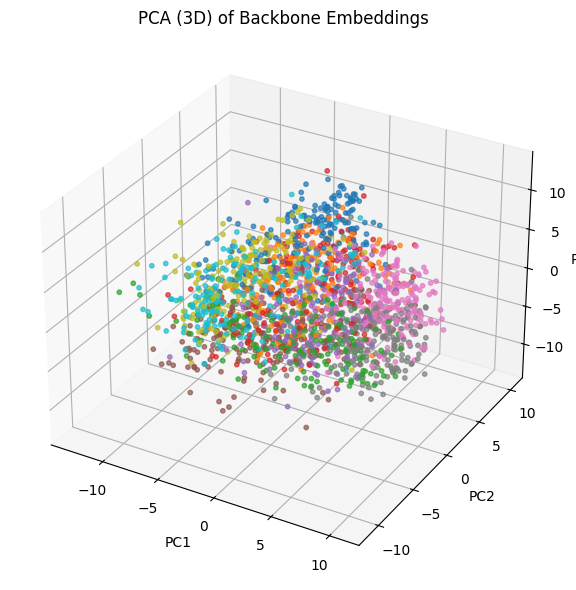

In [36]:
from mpl_toolkits.mplot3d import Axes3D

pca_3d = PCA(n_components=3)
features_3d = pca_3d.fit_transform(subset_features.numpy())

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    features_3d[:, 0],
    features_3d[:, 1],
    features_3d[:, 2],
    c=subset_labels,
    cmap="tab10",
    s=10,
    alpha=0.7
)

ax.set_title("PCA (3D) of Backbone Embeddings")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

plt.tight_layout()
plt.show()

### 7.3 Comparing projected vs backbone embeddings

LeJEPA operates on projected embeddings, but downstream tasks use backbone embeddings.
Comparing both helps understand how information is transformed.

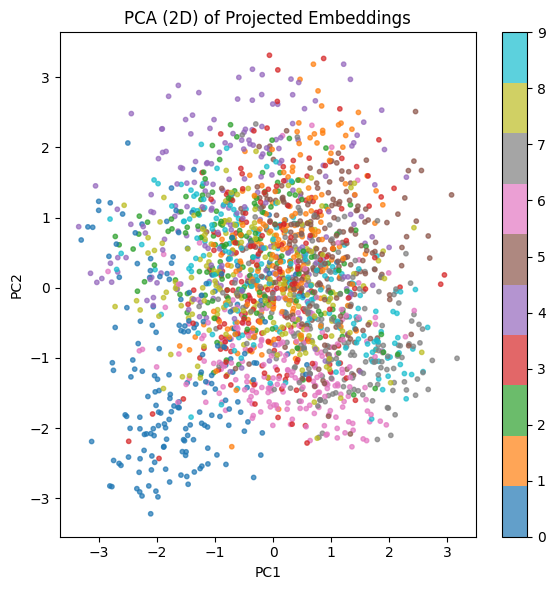

In [38]:
# Extract projected embeddings for the same subset
proj_subset = []

with torch.no_grad():
    for i in indices:
        img, label = test_dataset[i]
        img = img.to(device).unsqueeze(0)  # [1, 1, C, H, W]

        emb, proj = net(img)
        proj_subset.append(proj[0, 0].cpu())

proj_subset = torch.stack(proj_subset)

# PCA for projected embeddings
proj_2d = PCA(n_components=2).fit_transform(proj_subset.numpy())

plt.figure(figsize=(6, 6))
scatter = plt.scatter(
    proj_2d[:, 0],
    proj_2d[:, 1],
    c=subset_labels,
    cmap="tab10",
    s=10,
    alpha=0.7
)

plt.title("PCA (2D) of Projected Embeddings")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(scatter)
plt.tight_layout()
plt.show()

## Conclusion

This project explored JEPA by training a Vision Transformer using the LeJEPA objective, combining:

- an **invariance loss**, which encourages different augmented views of the same image to produce similar representations  
- the **SIGReg regularization**, which enforces a well-structured, approximately isotropic embedding space  

This combination addresses one of the central challenges in self-supervised learning:  
**learning meaningful representations without collapse**.



### Key Takeaways

- **Stable Representation Learning**  
  Unlike earlier JEPA-style approaches, LeJEPA introduces a principled regularization (SIGReg) that stabilizes training without requiring additional mechanisms such as momentum encoders.

- **Structured Latent Space**  
  The learned embeddings remain well-distributed, avoiding degeneracy while still capturing semantic structure.

- **Useful Features for Downstream Tasks**  
  The linear evaluation showed that the encoder learned features that are at least partially linearly separable, demonstrating practical usefulness.



### Challenges Encountered

- **Training Efficiency**  
  Multi-view augmentation and data loading can become a bottleneck, especially in constrained environments 

- **Sensitivity to Hyperparameters**  
  Batch size, number of views, and SIGReg parameters influence both stability and performance.

- **Compute Requirements**  
  Even with a smaller Vision Transformer, training remains computationally intensive.
